# openpilot supercombo on KITScenes: the scene sweep's config, run by paddock on every keyframe

The [scene-sweep notebook](openpilot_drv_supcombo_kitscenes_scene_sweep.ipynb)'s `CONFIG` was chosen through the analysis node on a few dozen keyframes. It does four things:

- it feeds the model the base front camera instead of the ring's, cut to 55° at comma's 1164x874;
- it shows the road as from a camera 1.22 times lower;
- it tilts the view 1.7° down;
- it sends the route as a turn desire.

Paddock then ran it itself, from a pairing table in the site config, on the 223 keyframes the stock run scored. This notebook reads that run beside two recorded ones:

- **stock** (`20260930T154018-242869`): nothing set. It is the [open-loop notebook](openpilot_drv_supcombo_kitscenes_openloop_analysis.ipynb)'s baseline.
- **intent** (`20260930T014333-d329a6`): the route as a desire, on the ring camera. It is the [four-questions note](openpilot_drv_supcombo_kitscenes_four_questions.md)'s Q1.
- **config** (`20261005T205400-a369d1`): the scene sweep's `CONFIG`.

For these runs it gives:

1. **Parameters.**
2. **What ran.** Each run's settings, and a check that paddock's run is the node's on the two keyframes both scored. Then the gate, set before the run: the config would become this site's default only if it beat stock.
3. **Overall.** The change on every keyframe, on the ones the config was tuned on, and on the ones it never saw, each with a 95 % interval over scenes. Then every metric, and a table of every keyframe.
4. **Per scene.** Which scenes got better and which got worse.
5. **The bad keyframes.** The config's worst plans and its largest losses, with the three largest drawn.
6. **Where.** By the car's speed, where most of the change is, then by the tags.
7. **The image against the desire.** The change on turns, split into the desire's share and the image's.
8. **What the model read.** Its camera height and its speed, against the four-questions note.
9. **One keyframe** (`FOCUS`).
10. **What this shows.**

Nothing here runs the model. Every number is read from the runs' records, so the notebook re-executes in seconds and cannot drift from what paddock recorded. The code is in [the config-run lib](openpilot_drv_supcombo_kitscenes_config_run_lib.py). The [note](openpilot_drv_supcombo_kitscenes_config_run.md) states the findings, with the strength of each claim.

**The config was tuned on part of the set it is scored on.** Of the 223 keyframes, 90 had a knob chosen or scored on them; part 3 lists where. The other 133 are held out. Every one of them is straight, because the desire was scored on every turn.

In [1]:
import os
import sys

import pandas as pd
from IPython.display import display

from paddock.config import REPO_ROOT

sys.path.insert(0, str(REPO_ROOT / "tools/models/openpilot/analysis"))  # the libs, beside this notebook
import openpilot_drv_supcombo_kitscenes_config_run_lib as C

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)  # the knobs a run set, and stock's failure modes, in full

## 1. Parameters

- **`RUNS`**: `{arm: run id}`, each a run of openpilot under `results/kitscenes/openpilot/`.
    - `"stock"` and `"config"` are required. `"intent"` is needed only by part 7.
    - Point `"config"` at another run to read it the same way. Every run must have scored the same keyframes.
- **`METRIC`**: what parts 3 to 7 compare. It is one of these, each in metres over the benchmark's 3 s:
    - `"ade"`;
    - `"fde_1s"`, `"fde_2s"` or `"fde_3s"`;
    - `"lat"` (lateral MAE) or `"lon"` (longitudinal MAE).
- **`ON`**: the keyframes parts 3 to 6 and 8 read. It can be:
    - a subset part 3 names, such as `"all"`, `"held out"`, `"turns"` or `"sweep60"`;
    - a keyframe, such as `"93bcdd59/40"`;
    - a scene prefix, such as `"3a616875"`;
    - a list of any of these.
- **`FOCUS`**: the keyframe part 9 draws.
- **`SORT`**: the column that sorts part 3's table of every keyframe. `"change"` is config − stock in `METRIC`.
- **`OVERRIDES`**: any of `C.PARAMS`, such as `{"tie_m": 0.1}`, `{"far_turn_m": 30.0}` or `{"speed_edges": (0, 6, 10, float("inf"))}`. Part 2 prints them all.
- **`TAGS`**: the stock run's tags table, which the open-loop notebook's §6 writes.
    - `"auto"` finds it under `{runs}`, and a path names it.
    - `None` goes without it. Part 6 then has only this notebook's own columns.
- **`WIDGETS`**: dropdowns in part 6. They are off by default because VS Code cannot draw a saved widget. Set `WIDGETS` here, or `PADDOCK_ANALYSIS_WIDGETS=1`, to turn them on.

In [2]:
RUNS = dict(C.RUNS)  # stock, intent and config, as above
METRIC = "ade"
ON = "all"
FOCUS = "93bcdd59/40"  # the largest gain: a straight at 13.7 m/s that stock planned from 9.7
SORT = "change"
OVERRIDES = {}
TAGS = "auto"
WIDGETS = os.environ.get("PADDOCK_ANALYSIS_WIDGETS") == "1"

## 2. What ran

Each run's settings and what openpilot's adapter reported about itself (`run.json`'s `provenance.policy`), one column per arm.

The config differs from stock in exactly what the pairing table sets: the front camera, the command source and four of the adapter's knobs. ONNX is pinned because the tinygrad backend refuses the cut. The weights, frames and sample list are the same.

In [3]:
C.WIDGETS = WIDGETS
study = C.Study(RUNS, tags=TAGS, overrides=OVERRIDES)
print("params, after OVERRIDES:", study.p)
study.provenance()

params, after OVERRIDES: {'v_go': 2.0, 'min_step_m': 0.25, 'curve_min_deg': 3.0, 'turn_pred_deg': 15.0, 'cam_h_split_m': 1.5, 'tie_m': 0.05, 'far_turn_m': 40.0, 'low_m': 1.39, 'high_m': 1.62, 'speed_edges': (0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, inf), 'n_boot': 2000, 'seed': 0}


,stock,intent,config
run id,20260930T154018-242869,20260930T014333-d329a6,20261005T205400-a369d1
valid,True,True,True
superseded by,,,
keyframes,223,223,223
ADE (m),1.595359,1.648641,1.248155
front camera,ring,ring,base
command source,straight,gt,gt
knobs set,none,DESIRE=turn,"BACKEND=onnx, HEIGHT_SCALE=1.22, PITCH_DEG=-1.7, FOV_DEG=55, DESIRE=turn"
backend,onnx,onnx,onnx
provider,CUDAExecutionProvider,CUDAExecutionProvider,CUDAExecutionProvider


**The oracle.** The scene-sweep notebook scored dbba76d9/40 and /130 through the analysis node, under stock and under its `CONFIG`. Paddock's runs must give the same ADE to the last bit. They use the same weights, frames, warp and desire, reached through paddock's adapter rather than the node's.

A `False` would mean paddock did not run the config the notebook chose. The check applies only to the runs in `C.RUNS`.

In [4]:
oracle = study.oracle()
if RUNS == C.RUNS:  # the oracle is the scene sweep's CONFIG; another config run has no reason to match it
    assert oracle.equal.all(), "paddock's run is not the node's on the oracle's keyframes"
oracle

node   paddock  equal
arm    keyframe                               
stock  dbba76d9/40   1.210846  1.210846   True
       dbba76d9/130  2.317540  2.317540   True
config dbba76d9/40   0.589518  0.589518   True
       dbba76d9/130  2.061548  2.061548   True

**The gate.** It was set before the run: the config becomes this site's default only if its mean ADE over the 223 keyframes is below stock's. That is the number `paddock report` ranks by.

`paddock run here measures as` asks a separate question.
- It builds the config that a plain `paddock run --bench kitscenes --model openpilot` would record under this site's `paddock.toml`, the way the runner builds it.
- It then names the run that config equals. That is `config` while the pairing tables are there, and `stock` once they are deleted.

In [5]:
study.gate()

stock ADE (m)                   1.595359
config ADE (m)                  1.248155
better                              True
config run valid                    True
config run superseded by                
a pairing table here                True
paddock run here measures as      config
Name: the gate, dtype: object

## 3. Overall

Where the config's knobs were chosen or scored (`C.CHOSEN`, `C.SCORED`). The lib restates each set from the cell of the notebook that defines it.

- **`sweep60`**: the open-loop notebook's height sweep (its §15) ran the first 60 keyframes by scene. s\* = 1.22 is what it measured there.
- **`ten`**: the image-calibration notebook's ten turns. There the height and the pitch were set on grids.
- **`five`**: five of the ten, in the image-tweak notebook. There the pitch, the camera, the cut and the desire were set by hand.
- **`scene sweep`**: dbba76d9. There the `CONFIG` was checked on every frame from 40 to 159.
- **`every turn`**: the desire was scored on all 39 turns before it was fixed, by the intent run and by the calibration notebook's §13.

The subsets built from these:
- **`tuned`** is the union of these sets.
- **`held out`** is everything else: 133 keyframes, every one straight.
- **`held-out scenes`** also drops every keyframe of a scene that had a tuned one, in case a scene's look carries from one keyframe to the next.
- **`turns not chosen on`** are the turns outside `CHOSEN`. Their desire was scored, but no knob was chosen on them.

In [6]:
study.subset_table()

,keyframes,scenes,turns,tuned
sweep60,60,37,10,60
ten,10,10,10,10
five,5,5,5,5
scene sweep,2,1,1,2
every turn,39,33,39,39
all,223,140,39,90
tuned,90,61,39,90
held out,133,94,0,0
held-out scenes,110,79,0,0
turns,39,33,39,39


The config against stock on each subset, in metres.

- `change` is config − stock, so negative is better.
- It has a 95 % interval from resampling scenes, because the keyframes of one scene are not independent.
- `better` and `worse` count the keyframes that moved by more than `tie_m`.
- The model is deterministic here: the oracle matches across two separate pipelines to the last bit. So the interval is the whole noise reference. It says how much the change depends on which scenes happen to be in the set.

In [7]:
study.overall(metric=METRIC).round(3)

,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
all,223,140,1.595,1.248,-0.347,-0.551,-0.136,-21.763,-31.732,-9.559,-0.361,129,83,11
tuned,90,61,1.558,1.495,-0.063,-0.404,0.259,-4.036,-22.750,19.028,-0.186,49,39,2
held out,133,94,1.620,1.081,-0.540,-0.810,-0.287,-33.300,-44.767,-19.993,-0.704,80,44,9
held-out scenes,110,79,1.620,1.053,-0.568,-0.819,-0.315,-35.043,-45.438,-22.155,-0.716,67,35,8
turns,39,33,1.724,1.958,0.234,-0.222,0.681,13.602,-11.359,46.853,-0.030,19,19,1
turns not chosen on,23,20,1.865,2.061,0.196,-0.321,0.806,10.511,-14.934,53.960,-0.030,11,11,1
near turns,30,26,1.657,1.879,0.223,-0.244,0.716,13.433,-12.494,55.162,0.098,14,15,1
far turns,9,8,1.947,2.221,0.274,-0.759,1.173,14.080,-33.794,78.301,-0.140,5,4,0
straight,184,128,1.568,1.098,-0.470,-0.693,-0.255,-30.002,-40.162,-18.039,-0.519,110,64,10


On each set a knob was chosen or scored on, one at a time:

In [8]:
study.overall(list(C.SEEN), metric=METRIC).round(3)

,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
sweep60,60,37,1.442,1.229,-0.213,-0.646,0.188,-14.781,-37.335,15.487,-0.250,34,25,1
ten,10,10,1.597,1.877,0.280,-0.276,0.831,17.529,-13.978,64.285,0.059,5,5,0
five,5,5,1.954,2.214,0.260,-0.615,1.307,13.280,-25.481,97.793,-0.107,3,2,0
scene sweep,2,1,1.764,1.326,-0.439,-0.439,-0.439,-24.865,-24.865,-24.865,-0.439,2,0,0
every turn,39,33,1.724,1.958,0.234,-0.222,0.681,13.602,-11.359,46.853,-0.030,19,19,1


Every metric on `ON`:

In [9]:
every = pd.DataFrame({C.METRICS[m]: study.paired(ON, metric=m) for m in C.METRICS}).T
every.astype({c: int for c in ("keyframes", "scenes", "better", "worse", "tie")}).round(3)

,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
ade,223,140,1.595,1.248,-0.347,-0.551,-0.136,-21.763,-31.732,-9.559,-0.361,129,83,11
fde@1s,223,140,0.828,0.618,-0.210,-0.331,-0.090,-25.360,-36.004,-11.616,-0.196,122,88,13
fde@2s,223,140,1.801,1.398,-0.403,-0.639,-0.157,-22.379,-32.550,-9.654,-0.474,125,86,12
fde@3s,223,140,2.904,2.355,-0.549,-0.919,-0.185,-18.912,-28.858,-6.780,-0.545,130,85,8
lateral_mae,223,140,0.286,0.339,0.053,0.028,0.082,18.602,9.867,29.234,0.010,42,81,100
longitudinal_mae,223,140,1.526,1.136,-0.390,-0.606,-0.167,-25.533,-36.074,-12.126,-0.384,129,83,11


**Every keyframe**, one row each, sorted by `SORT`. Each row says what the keyframe is, then gives each arm's metrics and readings as `<name>_<arm>`.

- `v` is the pose speed.
- `v0_*` is the first 0.5 s of the GT or of a plan.
- `cam_h_*` is the camera height the road head read.
- `dpsi_*` is the heading change toward the route's side, over 3 s (over 10 s for `dpsi_10s_*`).

Filter it like any DataFrame, e.g. `scores[scores.route == "left"]`.

In [10]:
scores = study.scores.assign(change=study.scores[f"{METRIC}_config"] - study.scores[f"{METRIC}_stock"])
scores = scores[study.mask(ON)].sort_values(SORT)
with pd.option_context("display.max_rows", len(scores)):
    display(scores.round(3))

,sample_id,scene,kf,split,route,turn_m,v,v_band,tuned,v0_gt,gt_dpsi,ade_stock,fde_1s_stock,fde_2s_stock,fde_3s_stock,lat_stock,lon_stock,v0_plan_stock,plan_v0_stock,head_stock,cam_h_stock,dpsi_stock,dpsi_10s_stock,ade_intent,fde_1s_intent,fde_2s_intent,fde_3s_intent,lat_intent,lon_intent,v0_plan_intent,plan_v0_intent,head_intent,cam_h_intent,dpsi_intent,dpsi_10s_intent,ade_config,fde_1s_config,fde_2s_config,fde_3s_config,lat_config,lon_config,v0_plan_config,plan_v0_config,head_config,cam_h_config,dpsi_config,dpsi_10s_config,change
label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
93bcdd59/40,kitscenes/val/93bcdd59-4141-3fed-17c7-7f1de5026f79/40,93bcdd59,40,val,straight,NaN,13.726,12+ m/s,False,13.881,-0.924,7.854,4.292,8.997,13.739,0.891,7.803,9.706,9.578,9.531,1.296,-3.206,-5.139,7.854,4.292,8.997,13.739,0.891,7.803,9.706,9.578,9.531,1.296,-3.206,-5.139,2.491,1.184,2.862,4.629,1.293,2.128,12.995,13.047,14.180,1.365,-4.090,-7.757,-5.363
97a94a07/40,kitscenes/val/97a94a07-e9a4-fc20-81aa-821b432cae7f/40,97a94a07,40,val,straight,NaN,13.648,12+ m/s,False,13.740,0.082,4.877,2.655,5.553,8.620,0.287,4.868,11.144,11.078,11.242,1.414,0.260,0.584,4.877,2.655,5.553,8.620,0.287,4.868,11.144,11.078,11.242,1.414,0.260,0.584,0.741,0.337,0.740,1.570,0.272,0.681,14.009,14.008,13.703,1.341,0.686,0.410,-4.135
2381584f/40,kitscenes/val/2381584f-2ac6-83c1-cfe8-cbf5b1d2cfda/40,2381584f,40,val,straight,NaN,14.588,12+ m/s,True,14.518,1.999,5.092,2.822,5.771,8.943,0.706,5.043,11.697,11.711,10.914,1.385,2.253,2.490,5.092,2.822,5.771,8.943,0.706,5.043,11.697,11.711,10.914,1.385,2.253,2.490,1.156,0.589,1.320,2.085,0.630,0.969,14.983,15.023,14.781,1.351,2.288,4.173,-3.936
873eebf4/40,kitscenes/overlap_train_val/873eebf4-448a-cf6e-7d5e-2dc1cd010723/40,873eebf4,40,overlap_train_val,straight,NaN,9.919,8-10 m/s,False,10.199,-0.635,4.714,2.435,5.353,8.625,0.177,4.710,8.071,8.094,7.863,1.414,0.489,0.720,4.714,2.435,5.353,8.625,0.177,4.710,8.071,8.094,7.863,1.414,0.489,0.720,0.781,0.518,0.950,1.182,0.248,0.736,9.960,10.000,10.375,1.381,0.536,1.183,-3.933
ba826f49/310,kitscenes/val/ba826f49-37df-54f1-1f9e-b3df77208a5d/310,ba826f49,310,val,straight,NaN,15.653,12+ m/s,False,15.689,-1.329,4.249,2.336,4.823,7.486,0.092,4.248,13.384,13.328,13.250,1.425,-1.148,-0.891,4.249,2.336,4.823,7.486,0.092,4.248,13.384,13.328,13.250,1.425,-1.148,-0.891,0.794,0.296,0.865,1.692,0.069,0.774,15.549,15.570,15.961,1.371,-0.451,-5.861,-3.456
2381584f/130,kitscenes/val/2381584f-2ac6-83c1-cfe8-cbf5b1d2cfda/130,2381584f,130,val,straight,NaN,13.762,12+ m/s,True,13.746,-1.847,5.025,2.900,5.741,8.548,0.259,5.018,10.822,10.773,10.305,1.384,-1.159,-1.500,5.025,2.900,5.741,8.548,0.259,5.018,10.822,10.773,10.305,1.384,-1.159,-1.500,1.653,0.767,1.773,3.304,0.393,1.603,14.447,14.453,14.102,1.354,-1.498,-2.818,-3.372
ba2f9a7d/130,kitscenes/val/ba2f9a7d-a115-9696-a431-72c7265413ff/130,ba2f9a7d,130,val,straight,NaN,13.535,12+ m/s,False,13.494,-0.532,4.081,2.403,4.713,6.777,0.405,4.060,11.061,11.023,11.055,1.421,-0.031,0.191,4.081,2.403,4.713,6.777,0.405,4.060,11.061,11.023,11.055,1.421,-0.031,0.191,0.813,0.469,0.885,1.453,0.485,0.650,13.857,13.891,13.695,1.363,0.030,1.219,-3.268
873eebf4/220,kitscenes/overlap_train_val/873eebf4-448a-cf6e-7d5e-2dc1cd010723/220,873eebf4,220,overlap_train_val,straight,NaN,9.844,8-10 m/s,False,9.958,3.909,4.065,2.571,4.782,6.345,0.319,4.052,7.367,7.309,7.484,1.359,3.907,3.777,4.065,2.571,4.782,6.345,0.319,4.052,7.367,7.309,7.484,1.359,3.907,3.777,1.243,0.965,1.571,1.483,0.228,1.221,9.009,9.039,9.375,1.351,4.215,5.123,-2.822
d96782f8/310,kitscenes/val/d96782f8-760b-8970-bfad-2a3552d207a4/310,d96782f8,310,val,straight,NaN,7.040,6-8 m/s,False,7.240,-3.599,3.526,1.973,4.094,5.995,0.445,3.497,5.334,5.176,5.125,1.363,-3.903,-10.118,3.526,1.973,4.094,5.995,0.445,3.497,5.334,5.176,5.125,1.363,-3.903,-10.118,0.820,0.430,1.005,1.351,0.404,0.713,6.933,6.840,6.871,1.362,-3.643,-5.631,-2.706


## 4. Per scene

- **Left:** every scene's change in mean `METRIC`, ranked. Dark bars are scenes with a tuned keyframe.
- **Right:** each scene's mean under the config against stock's, on log axes. Below the diagonal, the config is better.

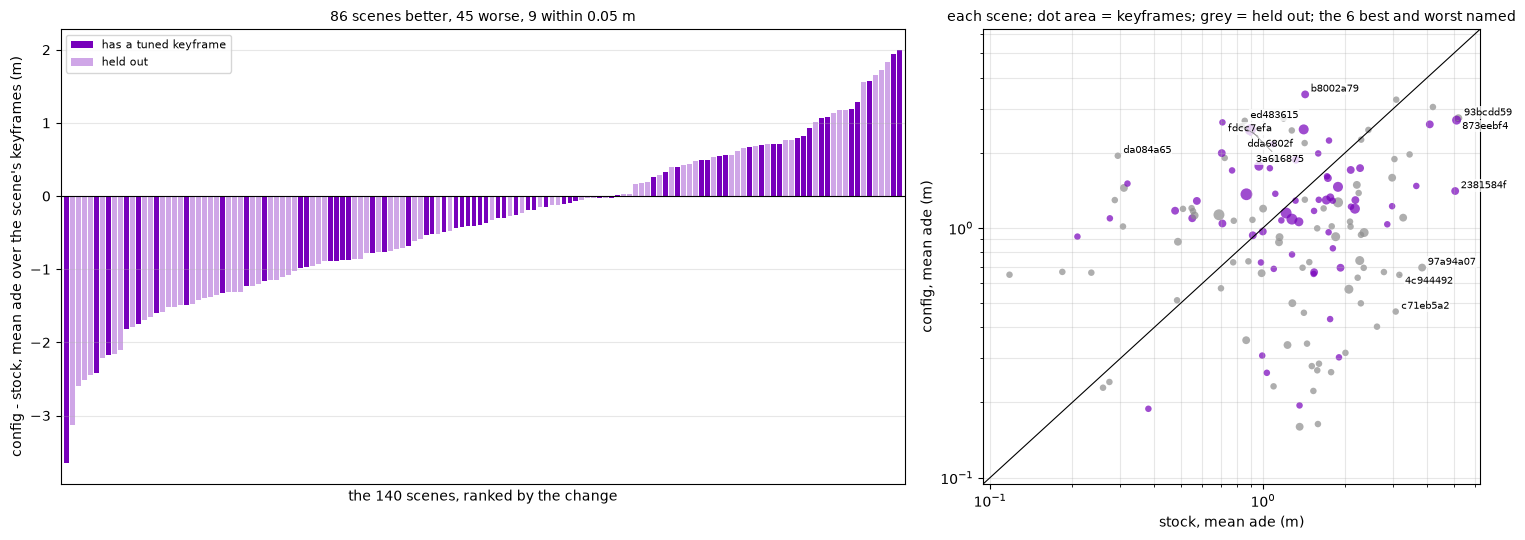

In [11]:
study.plot_scenes(metric=METRIC, on=ON)

In [12]:
scenes = study.by_scene(metric=METRIC, on=ON)
print("the 12 most improved scenes, then the 12 most worsened")
display(scenes.head(12).round(3))
scenes.tail(12)[::-1].round(3)

the 12 most improved scenes, then the 12 most worsened


,keyframes,routes,tuned,stock,intent,config,change,worst keyframe change,v
scene,,,,,,,,,
2381584f,2,2 straight,2,5.058,5.058,1.405,-3.654,-3.372,14.175
97a94a07,2,2 straight,0,3.827,3.827,0.693,-3.134,-2.132,12.449
c71eb5a2,1,1 straight,0,3.063,3.063,0.462,-2.601,-2.601,10.121
4c944492,1,1 straight,0,3.159,3.159,0.648,-2.510,-2.510,9.664
93bcdd59,2,2 straight,0,5.197,5.197,2.749,-2.448,0.466,12.287
873eebf4,3,"2 straight, 1 left",1,5.119,5.005,2.700,-2.419,-0.501,7.565
de354ef1,1,1 straight,0,2.616,2.616,0.402,-2.213,-2.213,8.150
0dd003b2,1,1 straight,1,3.644,3.644,1.472,-2.172,-2.172,12.771
c78f7cc6,2,2 straight,0,3.262,3.262,1.099,-2.163,-1.917,14.607


,keyframes,routes,tuned,stock,intent,config,change,worst keyframe change,v
scene,,,,,,,,,
b8002a79,2,2 right,2,1.427,4.830,3.423,1.996,3.059,13.664
fdcc7efa,1,1 left,1,0.710,2.453,2.645,1.935,1.935,8.046
ed483615,1,1 straight,0,0.857,0.857,2.683,1.826,1.826,3.805
dda6802f,1,1 straight,0,0.836,0.836,2.553,1.717,1.717,2.893
da084a65,1,1 straight,0,0.294,0.294,1.944,1.650,1.650,7.215
3a616875,5,"3 straight, 2 left",5,0.898,0.962,2.471,1.573,2.337,3.966
6370e4b6,1,1 straight,0,1.189,1.189,2.742,1.553,1.553,3.398
f0b1b61b,2,"1 straight, 1 right",1,0.706,1.096,1.993,1.286,1.761,4.716
236144ec,1,1 straight,1,0.319,0.319,1.504,1.186,1.186,3.155


## 5. The bad keyframes

The config's worst plans, then its largest losses against stock.

`stock's failure modes` are the open-loop notebook's tags on the stock run. They say what went wrong with stock's plan there, not with the config's.

In [13]:
study.worst(12, rank="config", metric=METRIC, on=ON).round(3)

,route,turn_m,v,tuned,ade_stock,ade_intent,ade_config,change,stock's failure modes
label,,,,,,,,,
873eebf4/130,left,9.0,2.931,True,6.578,6.237,6.077,-0.501,"under_brakes, understeer"
9ffae20c/310,straight,NaN,8.928,False,1.120,1.120,5.071,3.951,understeer
ba2f9a7d/40,right,54.0,7.101,True,4.085,4.777,4.381,0.296,ego_speed_misread
b8002a79/130,right,79.0,14.576,True,0.716,4.539,3.775,3.059,ego_speed_misread
e57f9b38/40,straight,NaN,2.337,False,3.077,3.077,3.261,0.184,ego_speed_misread
b8002a79/40,right,64.0,12.751,True,2.137,5.121,3.071,0.934,"too_slow_cruise, ego_speed_misread"
789908e0/40,straight,NaN,7.131,False,4.192,4.192,3.047,-1.145,"ego_speed_misread, turns_off_route"
93bcdd59/130,straight,NaN,10.848,False,2.540,2.540,3.006,0.466,ego_speed_misread
3a616875/40,straight,NaN,4.750,True,0.644,0.644,2.980,2.337,"too_fast_cruise, ego_speed_misread"


In [14]:
study.worst(15, rank="change", metric=METRIC, on=ON).round(3)

,route,turn_m,v,tuned,ade_stock,ade_intent,ade_config,change,stock's failure modes
label,,,,,,,,,
9ffae20c/310,straight,NaN,8.928,False,1.120,1.120,5.071,3.951,understeer
b8002a79/130,right,79.0,14.576,True,0.716,4.539,3.775,3.059,ego_speed_misread
3a616875/40,straight,NaN,4.750,True,0.644,0.644,2.980,2.337,"too_fast_cruise, ego_speed_misread"
3a616875/220,left,21.0,2.770,True,0.388,1.374,2.620,2.232,"ego_speed_misread, yaw_misread"
ba826f49/220,straight,NaN,12.704,False,0.748,0.748,2.945,2.197,understeer
d427b10f/40,straight,NaN,7.319,False,0.249,0.249,2.354,2.104,
8c501afb/40,left,17.0,4.211,True,0.743,2.304,2.696,1.953,"too_slow_cruise, understeer, ego_speed_misread, yaw_misread"
fdcc7efa/40,left,40.0,8.046,True,0.710,2.453,2.645,1.935,"too_slow_cruise, ego_speed_misread, yaw_misread"
ed483615/40,straight,NaN,3.805,False,0.857,0.857,2.683,1.826,"too_fast_cruise, ego_speed_misread"


The three largest losses, drawn. Each has three panels:
- every arm's plan against the GT, from above: solid within the benchmark's 3 s, dotted beyond;
- the keyframe from the ring's front camera, which stock and intent saw;
- the keyframe from the base camera, with the config's cut boxed.

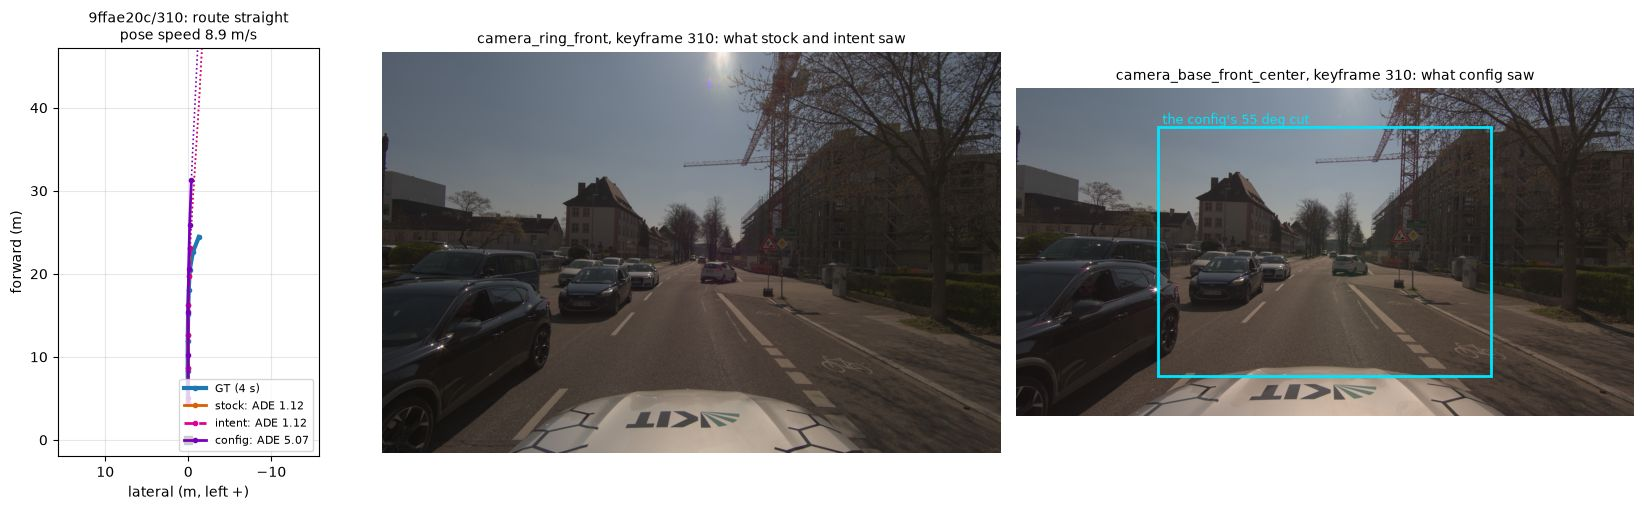

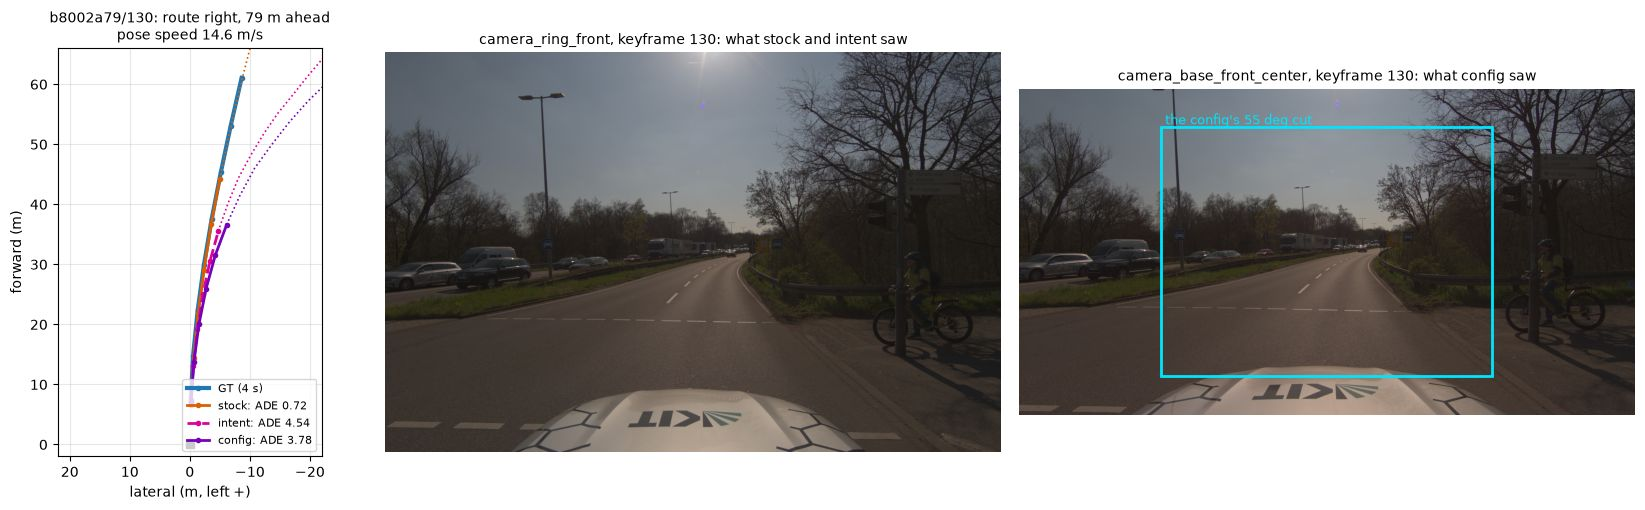

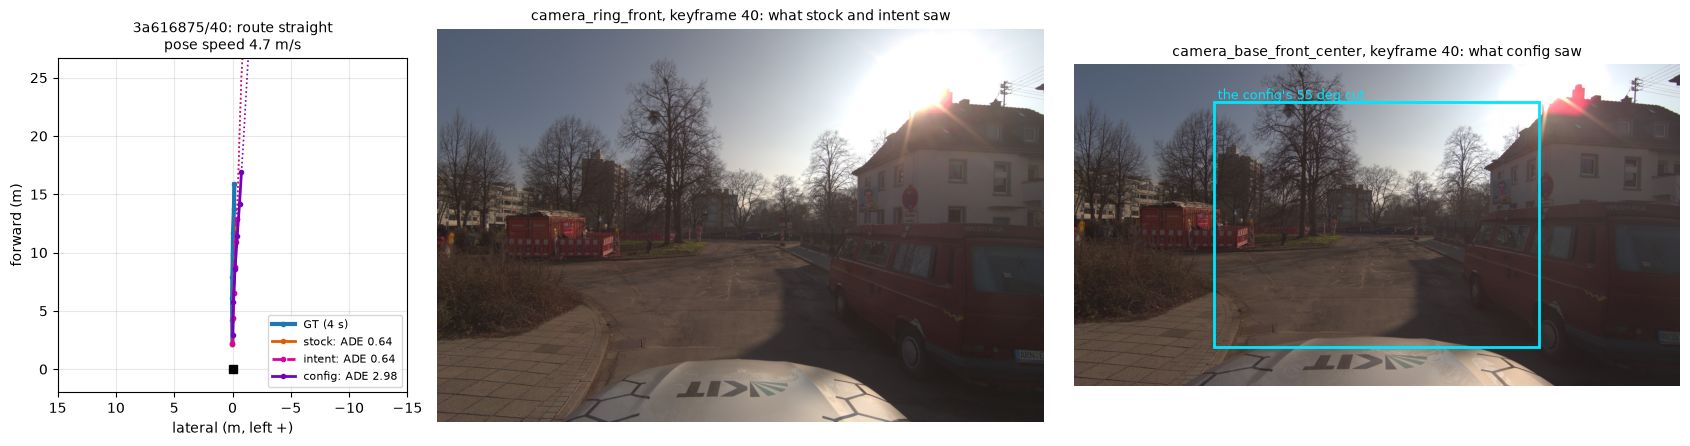

In [15]:
for key in study.worst(3, rank="change", metric=METRIC, on=ON).index:
    study.show(key)

## 6. Where: the car's speed, then the tags

Each band of the pose speed (`speed_edges`):
- **Left:** each arm's mean `METRIC`.
- **Right:** each arm's median plan for the first 0.5 s, against the GT's. The dashed line at 1 is a plan that starts at the right speed.

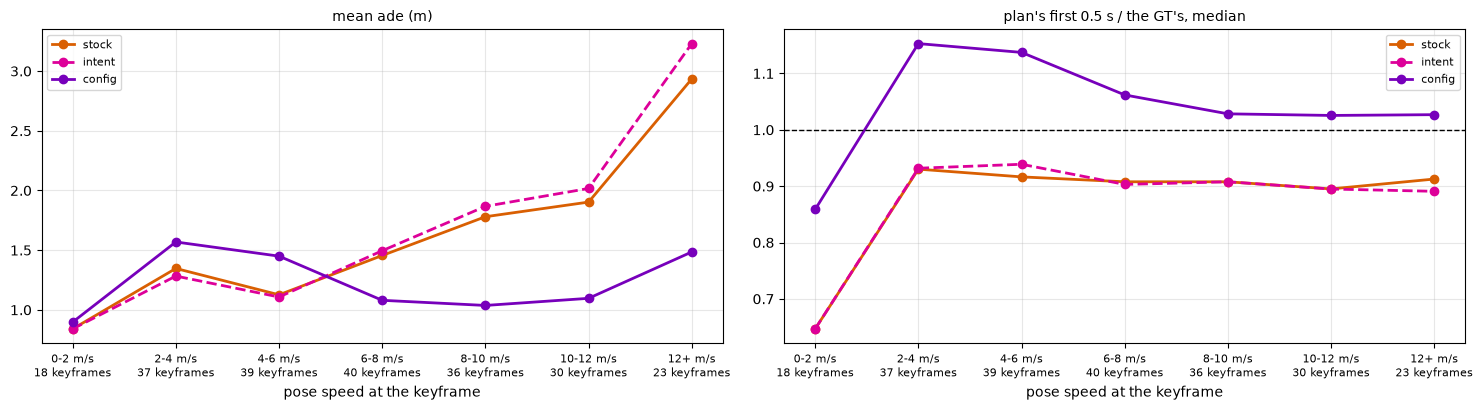

In [16]:
study.plot_speed(metric=METRIC, on=ON)

In [17]:
study.by_speed(metric=METRIC, on=ON).round(3)

,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie,"start / GT's, stock","start / GT's, config"
v_band,,,,,,,,,,,,,,,,
0-2 m/s,18,15,0.841,0.898,0.057,-0.205,0.247,6.772,-18.950,41.634,-0.009,5,7,6,0.647,0.859
2-4 m/s,37,34,1.347,1.569,0.222,-0.110,0.536,16.467,-6.992,47.954,0.111,15,19,3,0.930,1.153
4-6 m/s,39,34,1.126,1.450,0.324,0.016,0.625,28.748,1.215,62.319,0.491,17,22,0,0.916,1.137
6-8 m/s,40,36,1.455,1.080,-0.375,-0.693,-0.045,-25.792,-42.798,-3.509,-0.658,25,14,1,0.908,1.062
8-10 m/s,36,29,1.780,1.037,-0.743,-1.275,-0.288,-41.745,-60.047,-19.098,-1.082,26,10,0,0.908,1.028
10-12 m/s,30,27,1.903,1.097,-0.806,-1.185,-0.406,-42.364,-55.327,-24.211,-0.894,23,7,0,0.895,1.025
12+ m/s,23,18,2.934,1.485,-1.449,-2.312,-0.571,-49.389,-65.040,-23.605,-1.306,18,4,1,0.913,1.027


The stock run's tags break the change down by:
- the route;
- the GT's lateral and longitudinal shape;
- the tags' speed band;
- the lane markings;
- the setting;
- whether the car is already turning.

Any column of `study.scores` or `study.tags` works, e.g. `study.breakdown("split")`.

In [18]:
BY = ["route", "gt_lat", "gt_long", "speed_band", "lanes", "ctx_location", "ego_turning"]
for col in BY:
    if col in study.scores or col in study.tags:
        display(study.breakdown(col, metric=METRIC, on=ON).round(3))
    else:
        print(f"{col}: not here; it is a tags column, and TAGS found no table")

,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
route,,,,,,,,,,,,,,
straight,184,128,1.568,1.098,-0.470,-0.693,-0.255,-30.002,-40.162,-18.039,-0.519,110,64,10
left,21,20,1.756,2.056,0.300,-0.312,0.870,17.088,-14.215,63.757,0.817,10,11,0
right,18,15,1.685,1.843,0.158,-0.351,0.745,9.364,-18.229,52.057,-0.085,9,8,1


,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
gt_lat,,,,,,,,,,,,,,
straight,86,67,1.911,0.972,-0.939,-1.285,-0.628,-49.155,-57.916,-37.595,-0.855,63,21,2
curve_L,36,34,1.455,1.001,-0.454,-0.824,-0.108,-31.233,-49.208,-8.234,-0.707,22,11,3
curve_R,30,29,1.330,1.539,0.209,-0.360,0.804,15.747,-22.795,75.986,0.623,13,16,1
sharp_R,28,26,1.459,1.602,0.143,-0.168,0.468,9.782,-10.480,37.853,0.077,13,14,1
sharp_L,16,15,1.322,1.247,-0.075,-0.600,0.433,-5.666,-35.727,42.648,-0.154,9,7,0
turn_L,14,14,1.709,2.385,0.675,0.014,1.232,39.519,0.672,113.338,0.984,5,9,0
turn_R,10,9,1.282,1.405,0.123,-0.325,0.460,9.598,-18.720,44.742,0.102,4,5,1
na,3,3,0.133,0.117,-0.016,-0.030,-0.003,-12.243,-15.691,-6.768,-0.016,0,0,3


,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
gt_long,,,,,,,,,,,,,,
cruise,142,99,1.644,1.198,-0.446,-0.732,-0.194,-27.132,-39.590,-12.971,-0.421,85,51,6
brake,38,38,1.603,1.425,-0.178,-0.647,0.319,-11.105,-35.023,23.546,-0.357,21,16,1
accel,37,34,1.548,1.337,-0.211,-0.496,0.102,-13.623,-29.702,7.711,-0.467,22,15,0
starting,3,3,1.148,1.082,-0.066,-0.192,0.027,-5.742,-50.385,3.446,-0.033,1,0,2
stationary,2,2,0.149,0.132,-0.016,-0.030,-0.003,-11.048,-11.673,-6.768,-0.016,0,0,2
stopping,1,1,0.364,1.081,0.718,0.718,0.718,197.275,197.275,197.275,0.718,0,1,0


,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
speed_band,,,,,,,,,,,,,,
low,204,132,1.491,1.254,-0.237,-0.427,-0.038,-15.871,-26.581,-2.798,-0.321,117,82,5
mid,13,10,3.676,1.452,-2.224,-3.246,-0.902,-60.497,-73.101,-31.845,-2.408,11,1,1
standstill,6,6,0.641,0.599,-0.041,-0.106,0.002,-6.419,-35.473,0.326,-0.023,1,0,5


,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
lanes,,,,,,,,,,,,,,
none,166,109,1.536,1.301,-0.235,-0.450,-0.009,-15.309,-26.805,-0.616,-0.224,93,64,9
weak,49,40,1.566,1.112,-0.454,-0.940,0.019,-28.964,-50.561,1.345,-0.410,28,19,2
clear,8,6,3.013,0.991,-2.022,-2.902,-0.960,-67.102,-72.458,-56.216,-2.111,8,0,0


,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
ctx_location,,,,,,,,,,,,,,
urban,120,84,1.572,1.258,-0.314,-0.567,-0.055,-19.972,-32.484,-3.767,-0.370,68,47,5
nonurban,103,56,1.622,1.236,-0.386,-0.723,-0.061,-23.787,-38.607,-4.379,-0.305,61,36,6


,keyframes,scenes,stock,config,change,CI lo,CI hi,change %,% CI lo,% CI hi,median change,better,worse,tie
ego_turning,,,,,,,,,,,,,,
steady,167,118,1.590,1.079,-0.511,-0.741,-0.283,-32.112,-42.297,-19.854,-0.601,102,55,10
turning,56,46,1.612,1.751,0.140,-0.210,0.500,8.683,-11.853,35.233,0.077,27,28,1


In [19]:
study.explore(metric=METRIC)

WIDGETS is off: set WIDGETS = True in part 1 for dropdowns, or call study.breakdown(col, on=subset) and study.show(keyframe)


## 7. The image against the desire

- **On a straight route** the intent run sends no desire, so it is stock to the last bit. There, config − stock is the image alone.
- **On a turn**, intent − stock is the desire on the ring camera, and config − intent is the image with the desire sent. The two steps add up to `both`.

Near and far turns are split at `far_turn_m`: the distance from which the note's Q1 found the desire costing ADE.

In [20]:
study.decompose(metric=METRIC).round(3)

on the 184 straight keyframes, intent equals stock to the last bit on 184


what changes   from     to  \
keyframes  arms                                                            
straight   config - stock                  the image alone  1.568  1.098   
turns      intent - stock   the desire, on the ring camera  1.724  2.028   
           config - intent      the image, with the desire  2.028  1.958   
           config - stock                             both  1.724  1.958   
near turns intent - stock   the desire, on the ring camera  1.657  1.591   
           config - intent      the image, with the desire  1.591  1.879   
far turns  intent - stock   the desire, on the ring camera  1.947  3.487   
           config - intent      the image, with the desire  3.487  2.221   

                            change  CI lo  CI hi  better  worse  tie  
keyframes  arms                                                       
straight   config - stock   -0.470 -0.693 -0.255     110     64   10  
turns      intent - stock    0.305 -0.043  0.717      19     18    2  
           config - intent  -0.070 -0.502  0.343      16     21    2  
           config - stock    0.234 -0.222  0.681      19     19    1  
near turns intent - stock   -0.066 -0.299  0.156      17     11    2  
           config - intent   0.289 -0.163  0.694       8     20    2  
far turns  intent - stock    1.540  0.585  2.418       2      7    0  
           config - intent  -1.266 -1.974 -0.622       8      1    0

## 8. What the model read

The four-questions note found three things about stock:
- it reads its camera height in one of two modes, near 1.39 m or near 1.62 m (Q2);
- its pose head reads the speed 12 % slow (Q4);
- a height scale s\* = 1.22, measured on the ring camera, makes the head read the speed right (Q4).

The config shows the road as from a camera 1.22 times lower, but on the base camera. First, how high each front camera is, and how high the config's scale shows the road from:

In [21]:
study.heights().round(3)

,calibration (m),map (m),calibration / 1.22,map / 1.22,keyframes with a map height
ring,2.017,1.875,1.654,1.537,223
base,1.816,1.674,1.489,1.372,223


Then what each arm read, as medians: on `ON`, and on the turns alone.

In [22]:
study.readings(ON)

,stock,intent,config
camera height read (m),1.423,1.423,1.372
keyframes read under 1.5 m (low mode),130,130,223
pose head / pose speed,0.877,0.877,1.033
low mode,0.817,0.817,1.033
high mode,0.915,0.915,NaN
plan's first step / the GT's,0.909,0.909,1.051
low mode,0.875,0.888,1.051
high mode,0.921,0.918,NaN
"|plan's first step - the GT's| (m/s), mean",0.845,0.84,0.558
turns planned toward the route over 10 s,0.795,0.897,0.974


In [23]:
study.readings("turns")

,stock,intent,config
camera height read (m),1.385,1.385,1.359
keyframes read under 1.5 m (low mode),33,33,39
pose head / pose speed,0.818,0.818,1.042
low mode,0.794,0.794,1.042
high mode,0.935,0.935,NaN
plan's first step / the GT's,0.921,0.915,1.14
low mode,0.879,0.946,1.14
high mode,0.94,0.905,NaN
"|plan's first step - the GT's| (m/s), mean",0.743,0.715,0.877
turns planned toward the route over 10 s,0.795,0.897,0.974


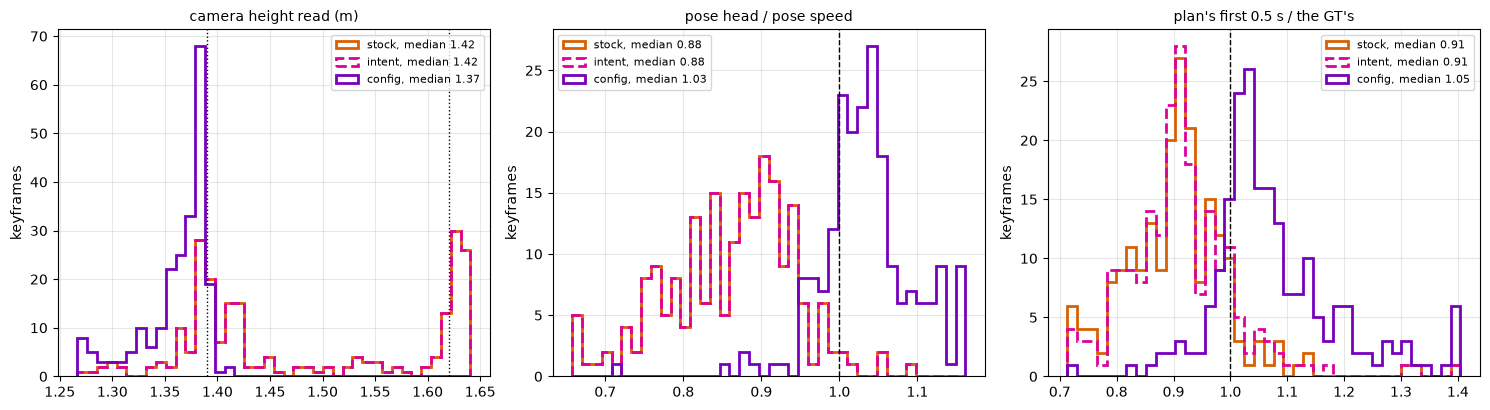

In [24]:
study.plot_readings(ON)

## 9. One keyframe (`FOCUS`)

Its plans and frames, then its row of part 3's table.

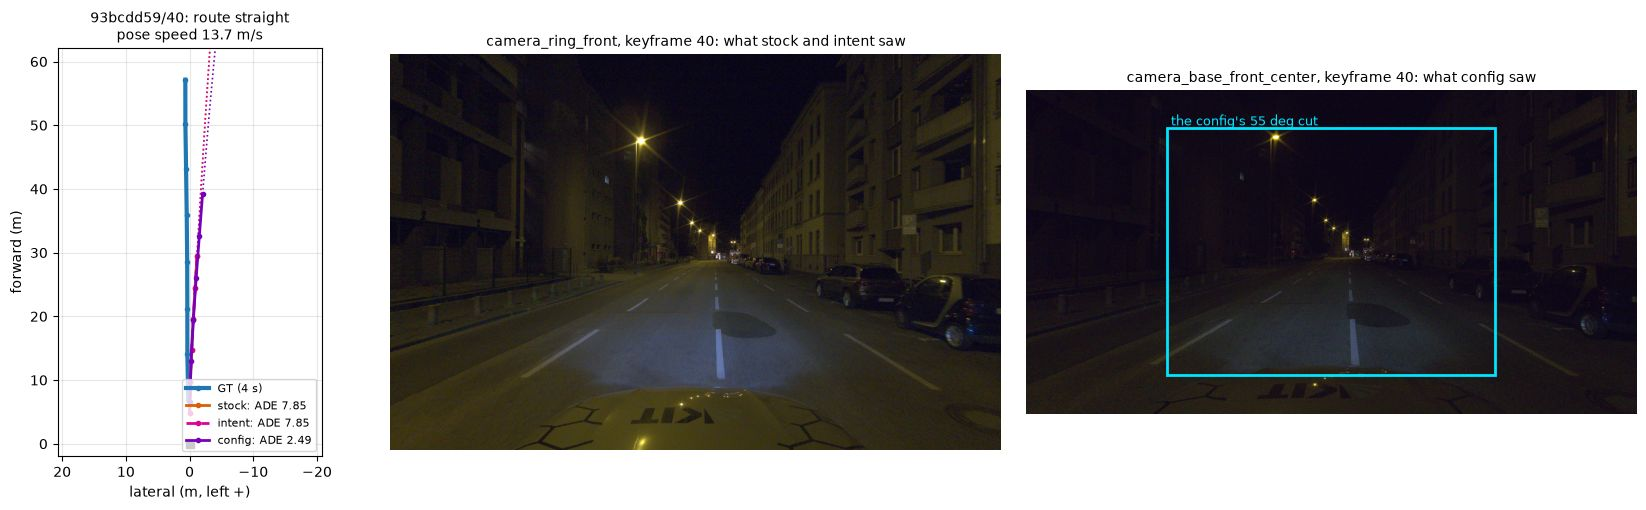

label,93bcdd59/40
sample_id,kitscenes/val/93bcdd59-4141-3fed-17c7-7f1de5026f79/40
scene,93bcdd59
kf,40
split,val
route,straight
turn_m,NaN
v,13.725992
v_band,12+ m/s
tuned,False
v0_gt,13.880986


In [25]:
study.show(FOCUS)
study.scores[study.mask(FOCUS)].T

## 10. What this shows

Read off the cells above on 2026-10-05. Rerunning with other `RUNS`, `ON` or `OVERRIDES` changes the numbers but not this text.

**Measured** (changes are config − stock, with 95% CIs from resampling scenes):

- **The run reproduces the scene sweep, and it beats stock.** On dbba76d9/40 and /130, paddock's ADE equals the analysis node's to the last bit, for stock and config alike (part 2). Over all 223 keyframes, ADE fell from 1.595 to 1.248 m. That is under stock's 1.595359, the bar fixed before the run, so this site's `paddock.toml` now carries the two pairing tables and a plain run measures this configuration.
- **Most of the gain is on keyframes no knob was chosen on** (part 3).
    - Overall: −0.347 m (CI −0.551 to −0.136; −21.8%), better on 129 keyframes and worse on 83.
    - On the 90 tuned keyframes, −0.063 (CI −0.404 to +0.259), which cannot be told from no change.
    - On the 133 held out, −0.540 (CI −0.810 to −0.287; −33%). On the 110 of those in scenes with no tuned keyframe, −0.568.
    - The sets the knobs were picked on did not all improve: sweep60 went −0.213, ten +0.280 and five +0.260.
- **Slow keyframes got worse and fast ones better, crossing at 6 m/s** (part 6).
    - The config raises the plan's start speed at every speed. Above 2 m/s, stock started at 0.895–0.930 of the GT's start speed. The config starts at 1.03 of it above 8 m/s, 1.06 at 6–8 m/s, and 1.14–1.15 at 2–6 m/s.
    - Above 6 m/s, ADE falls in every band, most at 12+ m/s: 2.934 → 1.485 m (−1.449, CI −2.312 to −0.571).
    - Below 6 m/s it rises: +0.057 at 0–2 m/s, +0.222 at 2–4 and +0.324 at 4–6. Only the last has a CI clear of zero (+0.016 to +0.625).
- **The gain is along the path, and across it the config is worse** (part 3).
    - Longitudinal MAE fell from 1.526 to 1.136 m (−25.5%).
    - Lateral MAE rose from 0.286 to 0.339 m (+0.053, CI +0.028 to +0.082; +18.6%). It got worse on 81 keyframes and better on 42.
    - FDE improved at every horizon. At 3 s it fell from 2.904 to 2.355 m.
- **Turns got worse, left turns most** (parts 3 and 6).
    - On the 39 turns: +0.234 m (CI −0.222 to +0.681), 19 better and 19 worse.
    - By the GT's shape, `turn_L` (14 keyframes) went +0.675 (CI +0.014 to +1.232; 5 better, 9 worse). It is the only shape whose CI lies above zero. `straight` went −0.939 (−49%) and `curve_L` −0.454.
    - Where the ego is already yawing (`ego_turning`, 56 keyframes), +0.140. Where it is steady (167), −0.511.
- **On turns, the image costs on near ones and the desire on far ones** (part 7). Intent equals stock to the last bit on all 184 straight keyframes, so the −0.470 on straights is the image alone. On turns, the two can be told apart:
    - **Within 40 m (30 turns).** The desire alone (intent − stock, on the ring camera) changes ADE by −0.066 (CI −0.299 to +0.156). The image, given the desire (config − intent), adds +0.289 (CI −0.163 to +0.694), worse on 20 and better on 8.
    - **Beyond 40 m (9 turns).** The desire alone costs +1.540 (CI +0.585 to +2.418; 7 worse). The image wins back −1.266 (CI −1.974 to −0.622; 8 better), leaving +0.274 against stock.
- **Where it helped and where it hurt** (part 4). Of 140 scenes, 86 got better, 45 worse, and 9 moved less than 0.05 m.
    - The 12 most improved scenes average 7.6–14.6 m/s. All are straights apart from one left turn in 873eebf4. The top three are 2381584f (5.058 → 1.405 m), 97a94a07 (3.827 → 0.693) and c71eb5a2 (3.063 → 0.462).
    - Seven of the 12 most worsened average under 5 m/s. The top three are b8002a79 (two right turns, 1.427 → 3.423), fdcc7efa (a left turn, 0.710 → 2.645) and ed483615 (a straight at 3.8 m/s, 0.857 → 2.683).
- **The especially bad keyframes** (part 5).
    - **873eebf4/130** is the config's worst plan, at 6.077 m: a left turn 9 m ahead at 2.9 m/s. Stock planned it worse (6.578), so the config did not cause it.
    - **9ffae20c/310** is the largest loss: +3.951 m (1.120 → 5.071), on a held-out straight at 8.9 m/s. From its figure, the GT slows and covers about 24 m in 4 s, while the config plans about 31 m in 3 s. Stock's plan stays near the GT.
    - **b8002a79/130** is a right turn 79 m ahead at 14.6 m/s: 0.716 → 3.775 m, with intent at 4.539. Told of the turn, the model turns its plan long before the road does, and the image wins back only part of that.
    - **3a616875**: all five of its keyframes are tuned, and three are among the 15 largest losses. At /40, a straight at 4.75 m/s, ADE went 0.644 → 2.980 m: the config plans about 17 m in 3 s where the GT covers 16 m in 4 s. /220 went +2.232 and /310 +1.707.
    - Stock's own plan was already too fast (its `too_fast_cruise` tag) on 5 of the 15 largest losses. There the config's faster start adds to an error stock already had.
- **The speed the model reads went from slow to slightly fast** (part 8).
    - Pose head / pose speed went 0.877 → 1.033.
    - The plan's first step / the GT's went 0.909 → 1.051, and its mean absolute error 0.845 → 0.558 m/s.
    - On the 39 turns the first step overshoots: 0.921 → 1.140, and its error rose from 0.743 to 0.877 m/s.
- **The camera-height reading is no longer bimodal** (part 8). The road head reads every keyframe in the low mode: 223 of 223 under 1.5 m, median 1.372 m, against stock's 130. The four-questions note measured that this mode hardly follows the image, and argued that it is a floor near 1.38 m. The base camera's map height over 1.22 is also 1.372 m, so this run cannot tell the floor from a true reading.
- **The base camera sits 0.20 m below the ring's** (part 8): map heights 1.674 against 1.875 m, calibration heights 1.816 against 2.017 m. At 1.22, the base camera's road is shown as from 1.372 m (map), against the ring's 1.537 m.

**Argued, not tested:**

- **1.22 was measured on the other camera.**
    - The four-questions note's rule is to show the road as from about 1.55 m. s\* = 1.22 was fitted on ring frames, where it does that.
    - On the base camera, 1.22 shows the road from 1.37 m, and a road seen from lower reads as faster. That fits the sign of the over-read: pose head 1.033, plan start 1.051.
    - It does not obviously explain the over-read's pattern: 1.14–1.15 at 2–6 m/s, but about 1.03 above 8 m/s.
    - By the same rule, the base camera wants s ≈ 1.08 (1.674 / 1.55). Testing that is one more run, and none was made.
- **The held-out number is a straight-road number.** Every turn was used to choose the desire, so all 133 held-out keyframes are straight. Turns have no held-out estimate. The nearest is the 23 turns the image knobs were not chosen on, though their desire was still scored: +0.196 (CI −0.321 to +0.806).
- **The turn numbers assume an oracle's route.** The config reads the route from the GT path (`command_source = "gt"`), as intent does, and a car would not have that. On far turns this hint arrives 40 m or more ahead, which is where the desire costs most.
- **About 7.4% of big_img is filler.** The 55° cut is narrower than big_img's 58.7°, so `big_img in bounds` is 0.926, and the rest is smeared from the cut's border. Whether the model reads that margin was not tested.